# Inteligencia Artificial. Tarea 2
**Nicole Bianculli y Taisir Ibrahim** · 28 de Octubre, 2026

**Dataset:** *Concrete Compressive Strength* (Kaggle / UCI).
Cada fila es una mezcla de concreto. Queremos predecir su **resistencia a la compresión** (MPa) a partir de sus ingredientes y su edad.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso

from my_ridge import MyRidge   # nuestra clase, está en my_ridge.py

# Función auxiliar: raíz del error cuadrático medio
def rmse(y_real, y_pred):
    return np.sqrt(np.mean((y_real - y_pred) ** 2))

RUTA = "concrete_data.csv"   # <-- cambia esto si tu archivo está en otra carpeta

## Punto 1. Datos, análisis exploratorio y sobreajuste

### 1.1 Cargar los datos

In [3]:
df = pd.read_csv(RUTA)
print("Forma original (filas, columnas):", df.shape)

# Le ponemos nombres cortos a las columnas (las 8 primeras son predictoras, la última es el objetivo)
assert df.shape[1] == 9, "Se esperaban 9 columnas (8 features + 1 objetivo)"
df.columns = ["cemento", "escoria", "ceniza", "agua", "superplastificante",
              "agregado_grueso", "agregado_fino", "edad", "resistencia"]
df.head()

Forma original (filas, columnas): (1030, 9)


,cemento,escoria,ceniza,agua,superplastificante,agregado_grueso,agregado_fino,edad,resistencia
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


### 1.2 Análisis exploratorio breve y limpieza
Revisamos: tipos de datos, valores faltantes, filas duplicadas y estadísticas básicas.

In [4]:
print(df.dtypes)
print("\nValores faltantes por columna:")
print(df.isnull().sum())
print("\nFilas duplicadas:", df.duplicated().sum())

cemento               float64
escoria               float64
ceniza                float64
agua                  float64
superplastificante    float64
agregado_grueso       float64
agregado_fino         float64
edad                    int64
resistencia           float64
dtype: object

Valores faltantes por columna:
cemento               0
escoria               0
ceniza                0
agua                  0
superplastificante    0
agregado_grueso       0
agregado_fino         0
edad                  0
resistencia           0
dtype: int64

Filas duplicadas: 25


In [5]:
# Limpieza: quitamos las filas duplicadas (no aportan información nueva)
df = df.drop_duplicates().reset_index(drop=True)
print("Forma después de limpiar:", df.shape)
assert len(df) >= 1000, "El enunciado pide al menos 1000 ejemplos"

df.describe()

Forma después de limpiar: (1005, 9)


,cemento,escoria,ceniza,agua,superplastificante,agregado_grueso,agregado_fino,edad,resistencia
count,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000
mean,278.631343,72.043483,55.536318,182.075323,6.033234,974.376816,772.688259,45.856716,35.250378
std,104.344261,86.170807,64.207969,21.339334,5.919967,77.579667,80.340435,63.734692,16.284815
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,190.700000,0.000000,0.000000,166.600000,0.000000,932.000000,724.300000,7.000000,23.520000
50%,265.000000,20.000000,0.000000,185.700000,6.100000,968.000000,780.000000,28.000000,33.800000
75%,349.000000,142.500000,118.300000,192.900000,10.000000,1031.000000,822.200000,56.000000,44.870000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


cemento               0.488283
superplastificante    0.344209
edad                  0.337367
escoria               0.103374
ceniza               -0.080648
agregado_grueso      -0.144717
agregado_fino        -0.186448
agua                 -0.269624
Name: resistencia, dtype: float64


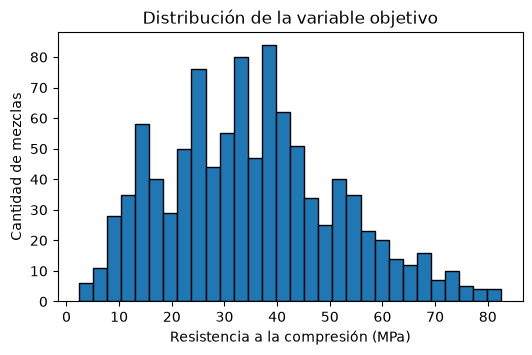

In [6]:
# Correlación de cada feature con la variable objetivo
print(df.corr()["resistencia"].drop("resistencia").sort_values(ascending=False))

# Distribución de la variable objetivo
plt.figure(figsize=(6, 3.5))
plt.hist(df["resistencia"], bins=30, edgecolor="black")
plt.xlabel("Resistencia a la compresión (MPa)")
plt.ylabel("Cantidad de mezclas")
plt.title("Distribución de la variable objetivo")
plt.show()

**Conclusiones del análisis exploratorio:** no hay valores faltantes; se eliminaron las filas repetidas; todas las features son numéricas.
El cemento y la edad son los que más se relacionan con la resistencia, y el agua tiene relación negativa (más agua → menos resistencia).

### 1.3 Separar entrenamiento y prueba, y provocar sobreajuste
Para que la regresión lineal **sobreajuste** usamos las dos ideas del enunciado a la vez:
1. Agregamos features con `PolynomialFeatures` (grado 2): pasamos de 8 a 44 columnas (las originales, sus cuadrados y los productos entre pares).
2. Usamos **muy pocos datos de entrenamiento** (80 filas). Con 44 columnas y solo 80 ejemplos, el modelo tiene casi tanta libertad como datos y termina "memorizando" el entrenamiento.

In [7]:
X = df.drop(columns="resistencia")
y = df["resistencia"].values

# Features polinomiales de grado 2 (sin la columna de unos; el intercepto lo maneja el modelo)
poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(X)
nombres = poly.get_feature_names_out()
print("Features originales:", X.shape[1], "-> con polinomios:", X_poly.shape[1])

# Conjunto de prueba = todo lo que no usamos para entrenar. Entrenamos con solo 80 filas.
X_train, X_test, y_train, y_test = train_test_split(
    X_poly, y, train_size=80, random_state=42)
print("Entrenamiento:", X_train.shape, " Prueba:", X_test.shape)

Features originales: 8 -> con polinomios: 44
Entrenamiento: (80, 44)  Prueba: (925, 44)


In [8]:
lin = LinearRegression().fit(X_train, y_train)

rmse_lin_train = rmse(y_train, lin.predict(X_train))
rmse_lin_test = rmse(y_test, lin.predict(X_test))

print(f"LinearRegression  RMSE entrenamiento: {rmse_lin_train:.3f}")
print(f"LinearRegression  RMSE prueba:        {rmse_lin_test:.3f}")

LinearRegression  RMSE entrenamiento: 4.721
LinearRegression  RMSE prueba:        19.122


**Sobreajuste:** el RMSE de entrenamiento es claramente menor que el de prueba (el modelo se ajusta demasiado a los 80 ejemplos y no generaliza a mezclas que no vio). Compara los dos números impresos arriba.

## Punto 2. Clase `MyRidge`

La clase está en el archivo **`my_ridge.py`** (solo usa `numpy`). Lo que hace, paso a paso:

1. **`fit`**: calcula la media de cada feature (`X_mean_`) y la media de la etiqueta (`y_mean_`) con los datos de entrenamiento.
2. Les resta esas medias a `X` y a `y` (centrar). Así el intercepto no se penaliza.
3. Resuelve $(X_c^T X_c + \lambda I)\,\theta = X_c^T y_c$ con `np.linalg.solve` y guarda el resultado en `coef_`.
4. Calcula el intercepto: $\theta_0 = \bar y - \bar x^T \theta$ y lo guarda en `intercept_`.
5. **`predict`**: $\hat y = (X - \bar x)\,\theta + \bar y$, usando siempre las medias guardadas en `fit`.
6. **`score`**: $R^2 = 1 - \frac{\sum (y-\hat y)^2}{\sum (y-\bar y)^2}$.
7. **`rmse`**: $\sqrt{\text{promedio}\,(y-\hat y)^2}$.

Prueba rápida de la clase con las 8 features originales (sin estandarizar):

In [9]:
X_orig = X.values
modelo_demo = MyRidge(alpha=1.0)
modelo_demo.fit(X_orig, y)

print("coef_:", np.round(modelo_demo.coef_, 4))
print("intercept_:", round(modelo_demo.intercept_, 4))
print("R2:", round(modelo_demo.score(X_orig, y), 4), " RMSE:", round(modelo_demo.rmse(X_orig, y), 4))

coef_: [ 0.1172  0.0995  0.0856 -0.1523  0.2849  0.0157  0.0183  0.1122]
intercept_: -17.9182
R2: 0.6039  RMSE: 10.2442


## Punto 3. Corregir el sobreajuste con `MyRidge`

### 3.1 Estandarizar las features
El `StandardScaler` se ajusta **solo con el entrenamiento** (para no "espiar" los datos de prueba) y luego se aplica a ambos conjuntos.

In [10]:
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

### 3.2 Escoger $\lambda$ por validación cruzada (5-fold)
Para cada valor de $\lambda$ de la grilla `np.logspace(-4, 4, 50)`:
- dividimos el entrenamiento en 5 partes; entrenamos con 4 y validamos con la que sobra (5 veces);
- promediamos el RMSE de entrenamiento y el de validación.

Nos quedamos con el $\lambda$ de menor RMSE de validación. **El conjunto de prueba no se toca aquí.**

In [11]:
lambdas = np.logspace(-4, 4, 50)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

rmse_train_cv = []
rmse_val_cv = []

for lam in lambdas:
    errores_train, errores_val = [], []
    for idx_tr, idx_va in kf.split(X_train_s):
        m = MyRidge(alpha=lam).fit(X_train_s[idx_tr], y_train[idx_tr])
        errores_train.append(m.rmse(X_train_s[idx_tr], y_train[idx_tr]))
        errores_val.append(m.rmse(X_train_s[idx_va], y_train[idx_va]))
    rmse_train_cv.append(np.mean(errores_train))
    rmse_val_cv.append(np.mean(errores_val))

mejor_lambda = lambdas[np.argmin(rmse_val_cv)]
print("Mejor lambda (menor RMSE de validación):", mejor_lambda)

Mejor lambda (menor RMSE de validación): 1.2067926406393288


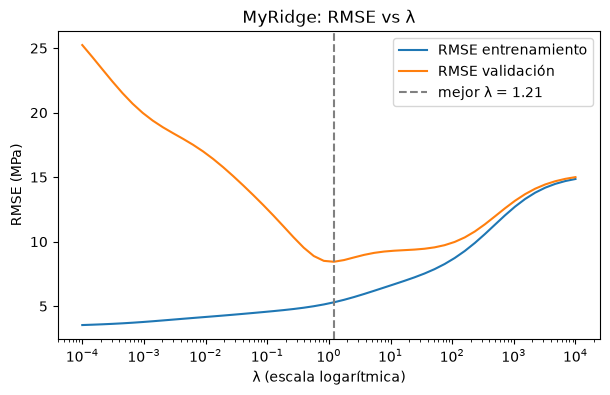

In [12]:
plt.figure(figsize=(7, 4))
plt.semilogx(lambdas, rmse_train_cv, label="RMSE entrenamiento")
plt.semilogx(lambdas, rmse_val_cv, label="RMSE validación")
plt.axvline(mejor_lambda, color="gray", linestyle="--", label=f"mejor λ = {mejor_lambda:.3g}")
plt.xlabel("λ (escala logarítmica)")
plt.ylabel("RMSE (MPa)")
plt.title("MyRidge: RMSE vs λ")
plt.legend()
plt.show()

**Cómo leer la gráfica:** con $\lambda$ muy pequeño el modelo es casi regresión lineal normal: error de entrenamiento bajo y de validación alto (sobreajuste). Al subir $\lambda$ el error de entrenamiento sube un poco pero el de validación baja. Si $\lambda$ es demasiado grande, los coeficientes se aplastan hacia 0 y ambos errores suben (subajuste). El mejor $\lambda$ está en el mínimo de la curva de validación.

### 3.3 Modelo final y RMSE de prueba (se reporta una sola vez)

In [13]:
ridge_final = MyRidge(alpha=mejor_lambda).fit(X_train_s, y_train)
rmse_ridge_test = ridge_final.rmse(X_test_s, y_test)

print(f"RMSE de prueba LinearRegression (punto 1): {rmse_lin_test:.3f}")
print(f"RMSE de prueba MyRidge (λ={mejor_lambda:.3g}):        {rmse_ridge_test:.3f}")

RMSE de prueba LinearRegression (punto 1): 19.122
RMSE de prueba MyRidge (λ=1.21):        10.898


**Comparación:** MyRidge con $\lambda$ escogido por validación debería dar un RMSE de prueba menor que el de la regresión lineal del punto 1 (compara los dos números). Eso es la regularización corrigiendo el sobreajuste.

### 3.4 Verificar contra `Ridge` de sklearn
Entrenamos las dos clases con los mismos datos y el mismo $\lambda$ y comparamos con `np.allclose`. Lo hacemos con features estandarizadas y sin estandarizar (usamos el conjunto de entrenamiento para no volver a mirar la prueba).

In [14]:
def comparar(X_tr, y_tr, lam, titulo):
    mio = MyRidge(alpha=lam).fit(X_tr, y_tr)
    sk = Ridge(alpha=lam).fit(X_tr, y_tr)

    print(titulo)
    print("  coef_ coinciden:     ", np.allclose(mio.coef_, sk.coef_))
    print("  intercept_ coinciden:", np.allclose(mio.intercept_, sk.intercept_))
    print("  R2 coinciden:        ", np.allclose(mio.score(X_tr, y_tr), sk.score(X_tr, y_tr)))
    print("  RMSE coinciden:      ", np.allclose(mio.rmse(X_tr, y_tr), rmse(y_tr, sk.predict(X_tr))))

comparar(X_train_s, y_train, mejor_lambda, "Con features estandarizadas:")
comparar(X_train, y_train, mejor_lambda, "Con features SIN estandarizar:")

Con features estandarizadas:
  coef_ coinciden:      True
  intercept_ coinciden: True
  R2 coinciden:         True
  RMSE coinciden:       True
Con features SIN estandarizar:
  coef_ coinciden:      True
  intercept_ coinciden: True
  R2 coinciden:         True
  RMSE coinciden:       True


Si todo da `True`, nuestra implementación de la fórmula cerrada hace lo mismo que `Ridge` de sklearn, incluso sin estandarizar (porque centramos dentro de `fit`).

## Punto 4. Ridge vs. Lasso

Usamos los mismos datos estandarizados. Cada modelo escoge **su propio** `alpha` por validación cruzada con `GridSearchCV` (porque Lasso tiene el factor $\frac{1}{2m}$ y el mismo número no significa lo mismo en los dos modelos).

In [15]:
# Ridge: misma grilla que en el punto 3
grid_ridge = GridSearchCV(Ridge(), {"alpha": np.logspace(-4, 4, 50)},
                          cv=kf, scoring="neg_root_mean_squared_error")
grid_ridge.fit(X_train_s, y_train)

# Lasso: alphas más pequeños; subimos max_iter para evitar ConvergenceWarning
grid_lasso = GridSearchCV(Lasso(max_iter=100000), {"alpha": np.logspace(-3, 1, 50)},
                          cv=kf, scoring="neg_root_mean_squared_error")
grid_lasso.fit(X_train_s, y_train)

ridge_sk = grid_ridge.best_estimator_
lasso_sk = grid_lasso.best_estimator_
print("Mejor alpha Ridge:", grid_ridge.best_params_["alpha"])
print("Mejor alpha Lasso:", grid_lasso.best_params_["alpha"])

d:\r\D\IA_TRABAJOS\Tarea2\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.573789e+01, tolerance: 1.484e+00
  model = cd_fast.enet_coordinate_descent(
d:\r\D\IA_TRABAJOS\Tarea2\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.664665e+02, tolerance: 1.537e+00
  model = cd_fast.enet_coordinate_descent(
d:\r\D\IA_TRABAJOS\Tarea2\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duali

Mejor alpha Ridge: 1.2067926406393288
Mejor alpha Lasso: 0.13257113655901082


### 4.1 Tabla de coeficientes lado a lado

In [16]:
tabla = pd.DataFrame({
    "MyRidge": ridge_final.coef_,
    "Ridge (sklearn)": ridge_sk.coef_,
    "Lasso (sklearn)": lasso_sk.coef_,
}, index=nombres)

pd.set_option("display.max_rows", None)
tabla.round(4)

,MyRidge,Ridge (sklearn),Lasso (sklearn)
cemento,1.3090,1.3090,0.0000
escoria,0.7482,0.7482,0.0000
ceniza,0.8856,0.8856,0.0000
agua,-1.2734,-1.2734,0.0000
superplastificante,-0.0811,-0.0811,-0.0000
agregado_grueso,-0.4095,-0.4095,-0.0000
agregado_fino,0.3251,0.3251,-0.0000
edad,3.0805,3.0805,0.0000
cemento^2,-1.8576,-1.8576,0.0000
cemento escoria,2.7348,2.7348,3.9237


(MyRidge usa el $\lambda$ del punto 3, que viene de la misma validación que `GridSearchCV` hizo para Ridge, por eso sus coeficientes son casi idénticos a los de Ridge de sklearn.)

### 4.2 Caminos de coeficientes
Entrenamos cada modelo con muchos valores de $\lambda$ y dibujamos cómo cambia cada coeficiente (una línea por feature).

d:\r\D\IA_TRABAJOS\Tarea2\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.692031e+01, tolerance: 1.859e+00
  model = cd_fast.enet_coordinate_descent(
d:\r\D\IA_TRABAJOS\Tarea2\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.811986e+01, tolerance: 1.859e+00
  model = cd_fast.enet_coordinate_descent(
d:\r\D\IA_TRABAJOS\Tarea2\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duali

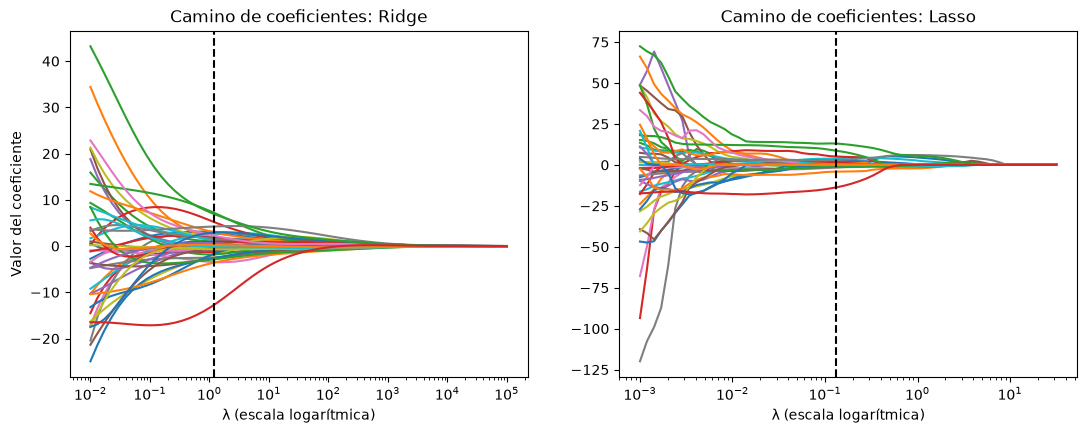

In [17]:
alphas_ridge = np.logspace(-2, 5, 60)
alphas_lasso = np.logspace(-3, 1.5, 60)

camino_ridge = np.array([Ridge(alpha=a).fit(X_train_s, y_train).coef_ for a in alphas_ridge])
camino_lasso = np.array([Lasso(alpha=a, max_iter=100000).fit(X_train_s, y_train).coef_ for a in alphas_lasso])

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))

ejes[0].semilogx(alphas_ridge, camino_ridge)
ejes[0].axvline(grid_ridge.best_params_["alpha"], color="black", linestyle="--")
ejes[0].set_title("Camino de coeficientes: Ridge")
ejes[0].set_xlabel("λ (escala logarítmica)")
ejes[0].set_ylabel("Valor del coeficiente")

ejes[1].semilogx(alphas_lasso, camino_lasso)
ejes[1].axvline(grid_lasso.best_params_["alpha"], color="black", linestyle="--")
ejes[1].set_title("Camino de coeficientes: Lasso")
ejes[1].set_xlabel("λ (escala logarítmica)")

plt.show()

(La línea punteada marca el $\lambda$ elegido por validación.) En **Ridge** los coeficientes se encogen suave hacia 0 pero ninguno llega a ser exactamente 0. En **Lasso** las líneas llegan a 0 y se quedan pegadas ahí: las features salen del modelo una por una.

### 4.3 Coeficientes de Lasso iguales a cero y comparación de RMSE

In [18]:
coef_lasso = lasso_sk.coef_
es_cero = (coef_lasso == 0)

print(f"Lasso: {es_cero.sum()} de {len(coef_lasso)} coeficientes son exactamente 0")
print(f"Ridge: {(ridge_sk.coef_ == 0).sum()} de {len(ridge_sk.coef_)} coeficientes son exactamente 0")

print("\nFeatures que Lasso ELIMINA:")
print(list(nombres[es_cero]))

print("\nFeatures que Lasso CONSERVA:")
print(list(nombres[~es_cero]))

Lasso: 25 de 44 coeficientes son exactamente 0
Ridge: 0 de 44 coeficientes son exactamente 0

Features que Lasso ELIMINA:
['cemento', 'escoria', 'ceniza', 'agua', 'superplastificante', 'agregado_grueso', 'agregado_fino', 'edad', 'cemento^2', 'cemento superplastificante', 'cemento agregado_fino', 'cemento edad', 'escoria agua', 'escoria agregado_grueso', 'ceniza agua', 'ceniza agregado_grueso', 'ceniza agregado_fino', 'agua^2', 'agua edad', 'superplastificante^2', 'superplastificante agregado_grueso', 'superplastificante agregado_fino', 'agregado_grueso^2', 'agregado_grueso edad', 'agregado_fino^2']

Features que Lasso CONSERVA:
['cemento escoria', 'cemento ceniza', 'cemento agua', 'cemento agregado_grueso', 'escoria^2', 'escoria ceniza', 'escoria superplastificante', 'escoria agregado_fino', 'escoria edad', 'ceniza^2', 'ceniza superplastificante', 'ceniza edad', 'agua superplastificante', 'agua agregado_grueso', 'agua agregado_fino', 'superplastificante edad', 'agregado_grueso agregado

In [19]:
resumen = pd.DataFrame({
    "alpha elegido": [None, mejor_lambda, grid_ridge.best_params_["alpha"], grid_lasso.best_params_["alpha"]],
    "RMSE prueba": [rmse_lin_test,
                    ridge_final.rmse(X_test_s, y_test),
                    rmse(y_test, ridge_sk.predict(X_test_s)),
                    rmse(y_test, lasso_sk.predict(X_test_s))],
}, index=["LinearRegression (punto 1)", "MyRidge", "Ridge (sklearn)", "Lasso (sklearn)"])
resumen.round(3)

,alpha elegido,RMSE prueba
LinearRegression (punto 1),NaN,19.122
MyRidge,1.207,10.898
Ridge (sklearn),1.207,10.898
Lasso (sklearn),0.133,10.836


**Comparación:** Mira la tabla: Ridge y Lasso deberían tener un RMSE de prueba menor que la regresión lineal sin regularizar. Entre ellos suelen quedar parecidos; la diferencia es que Lasso usa **menos features** (las que no elimina), lo que da un modelo más fácil de interpretar.

### 4.4 ¿Por qué Lasso produce ceros exactos y Ridge no?
Ambos modelos minimizan "error de ajuste + penalización". Es equivalente verlo como minimizar el error **dentro de una región** permitida para los coeficientes:

- **Ridge** (penalización $\sum w_j^2$): la región es un **círculo** (una esfera en más dimensiones).
- **Lasso** (penalización $\sum |w_j|$): la región es un **rombo** (diamante).

Las curvas de igual error son **elipses** centradas en la solución de mínimos cuadrados (la de sin regularizar). La solución regularizada es el **primer punto donde la elipse toca la región**.

- El círculo es liso y no tiene esquinas: la elipse lo toca en un punto cualquiera, y es casi imposible que ese punto caiga exactamente sobre un eje (donde un coeficiente vale 0).
- El rombo tiene **esquinas justo sobre los ejes**. Una elipse que se aproxima desde afuera muy frecuentemente toca primero una esquina, y en una esquina uno o más coeficientes valen exactamente 0.

Otra forma de verlo (con derivadas): la fuerza de la penalización Ridge es $2\lambda w_j$, que se hace pequeña cuando $w_j$ se acerca a 0, así que no logra llevarlo del todo a 0. En Lasso la fuerza es $\lambda\,\text{signo}(w_j)$, constante aunque $w_j$ sea diminuto, y puede "vencer" a la señal del dato y dejar $w_j$ exactamente en 0.